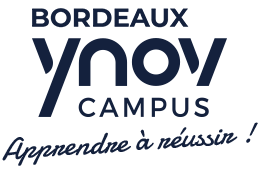

# TP1 — NumPy avancé, exploration + PCA, régression logistique from scratch

> **Cours Deep Learning · Ynov Bordeaux · EIA Mastère 2** — TP1 (J1)
> 3h · Livrable : notebook complété avec courbes (coût, accuracy, α), projection PCA 2D et variance cumulée

**Comment travailler :** exécutez les cellules dans l'ordre. Les cellules marquées `# TODO` sont à compléter. Utilisez `assert` sur les formes dès que vous manipulez des tenseurs. Une cellule à compléter échoue tant que son `TODO` n'est pas fait : c'est normal. Le TP se termine en séance et le corrigé est distribué en fin de TP ; il n'y a rien à rendre.

## Partie 0 — Cadrer avant de coder (5 min)

Avant la première ligne de NumPy, les réflexes du cours du matin. Répondez en commentaire dans la cellule : le type d'apprentissage, la métrique, la baseline. Le jeu de données du TP est Fashion-MNIST : 70 000 images 28 × 28 en niveaux de gris, dix catégories de vêtements.

In [1]:
# 1. Type d'apprentissage
#    - Partie C (T-shirt vs Pantalon) : apprentissage SUPERVISÉ (on dispose des étiquettes y),
#      de type CLASSIFICATION BINAIRE (sortie discrète : 0 ou 1, la sortie du modèle est une probabilité P(y=1|x)).
#    - Partie B (PCA) : apprentissage NON SUPERVISÉ (les étiquettes ne servent pas à calculer les composantes,
#      seulement à colorier le scatter) ; c'est de la réduction de dimension, ni régression ni classification.
#
# 2. Métriques
#    - Métrique d'apprentissage (ce que le modèle minimise) : la perte logistique (entropie croisée binaire) moyenne,
#      J = -1/m * somme[ y*log(a) + (1-y)*log(1-a) ] : différentiable, donc exploitable par la descente de gradient.
#    - Métrique de décision (ce qu'on regarde pour comparer) : l'accuracy sur le jeu de dev (pas sur le train, pas sur le test).
#      Elle est adaptée ici car les deux classes sont équilibrées (~50/50) et les erreurs ont le même coût.
#
# 3. Baseline à battre
#    - Règle 1 : prédire toujours la classe majoritaire. Les classes de Fashion-MNIST étant équilibrées,
#      T-shirt vs Pantalon donne ~50 % d'accuracy (et 10 % pour les 10 classes).
#    - Règle 2 (bon sens) : « image plus sombre que la médiane du train -> pantalon », car un pantalon a moins de pixels allumés.
#      Cette règle sans apprentissage fait mieux que 50 % (mesurée en C0) ; le modèle doit la dépasser pour justifier sa complexité.
#
# 4. Forme de X dans la notation du cours (un exemple par colonne)
#    - X : (n_x, m) = (784, m), avec n_x = 28 * 28 = 784 pixels par image et m le nombre d'images.
#    - Y : (1, m). On passe de (m, 28, 28) à (784, m) par reshape(m, -1).T


## Partie A — NumPy avancé (45 min)

Objectif : ne plus jamais écrire de boucle `for` sur des nombres, et vérifier systématiquement les formes.

In [2]:
import numpy as np, time, matplotlib.pyplot as plt
rng = np.random.default_rng(0)

### A1. Reshape d'un batch d'images
Un batch de 8 images 28×28 en niveaux de gris doit devenir une matrice `X` de forme `(784, 8)` (convention du cours : un exemple par colonne).

In [3]:
imgs = rng.integers(0, 256, size=(8, 28, 28)).astype("float32")     # (m, H, W)
X = imgs.reshape(8, -1).T / 255.0
assert X.shape == (784, 8)
assert np.allclose(X[:, 3], imgs[3].ravel() / 255.0)


### A2. Broadcasting
Centrer chaque **feature** (ligne de X) et normaliser des colonnes pour qu'elles somment à 1, sans boucle.

In [4]:
mu = X.mean(axis=1, keepdims=True)
Xc = X - mu
assert Xc.shape == X.shape and np.allclose(Xc.mean(axis=1), 0, atol=1e-6)

A = rng.random((3, 4))
A_pct = A / A.sum(axis=0, keepdims=True)
assert np.allclose(A_pct.sum(axis=0), 1)


### A3. `einsum` et produits
Réécrire un produit matriciel, un produit scalaire par colonne et une somme de produits externes avec `np.einsum`.

In [5]:
W = rng.normal(size=(4, 784)); B = rng.normal(size=(784, 8))
Z2 = np.einsum("ij,jk->ik", W, B)
assert np.allclose(W @ B, Z2)
dots = np.einsum("ij,ij->j", B, B)
assert np.allclose(dots, (B * B).sum(axis=0))


### A4. Benchmark : boucle vs vectorisé

In [6]:
a, b = rng.random(1_000_000), rng.random(1_000_000)
t0 = time.perf_counter(); s = 0.0
for i in range(len(a)): s += a[i] * b[i]
t_loop = time.perf_counter() - t0
t0 = time.perf_counter(); s2 = np.dot(a, b); t_vec = time.perf_counter() - t0
print(f"boucle : {t_loop*1000:.1f} ms | vectorisé : {t_vec*1000:.3f} ms | facteur x{t_loop/t_vec:.0f}")
assert abs(s - s2) < 1e-6 * abs(s2) + 1e-6

boucle : 219.0 ms | vectorisé : 24.617 ms | facteur x9


### A5. Le piège du vecteur « rang 1 »
Montrez que `a.T` ne fait rien sur un `(5,)` et corrigez avec `reshape`.

In [7]:
a = rng.normal(size=5)
print(a.shape, a.T.shape)      # que remarquez-vous ? -> (5,) (5,) : la transposée ne change rien sur un tableau 1D
a = a.reshape(5, 1)            # en faire un vecteur colonne (5, 1)
assert a.shape == (5, 1)


(5,) (5,)


## Partie B — Exploration et PCA sur Fashion-MNIST (60 min)

In [8]:
# Fashion-MNIST : 70 000 images 28 x 28 en niveaux de gris, 10 classes. Via torchvision si disponible, sinon via scikit-learn (OpenML).
CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
try:
    from torchvision import datasets
    train_ds = datasets.FashionMNIST("data", train=True, download=True)
    test_ds  = datasets.FashionMNIST("data", train=False, download=True)
    X_all = train_ds.data.numpy().reshape(len(train_ds), -1).astype("float32") / 255.0   # (60000, 784), pixels ramenés dans [0, 1]
    y_all = train_ds.targets.numpy()
    X_test = test_ds.data.numpy().reshape(len(test_ds), -1).astype("float32") / 255.0
    y_test = test_ds.targets.numpy()
except (ImportError, OSError):   # OSError : torch installé mais DLL introuvable sous Windows (WinError 127)
    import ssl, certifi
    # Le magasin de certificats Windows contient un certificat illisible (SSLError ASN1) : on utilise le bundle certifi
    ssl._create_default_https_context = lambda *a, **k: ssl.create_default_context(cafile=certifi.where())
    from sklearn.datasets import fetch_openml
    fm = fetch_openml("Fashion-MNIST", version=1, as_frame=False, parser="auto")        # 70 000 x 784, téléchargement de 30 Mo
    Xf = fm.data.astype("float32") / 255.0; yf = fm.target.astype(int)
    X_all, y_all, X_test, y_test = Xf[:60000], yf[:60000], Xf[60000:], yf[60000:]
# split train / dev (le test reste intouché jusqu'à la fin)
rng = np.random.default_rng(0); idx = rng.permutation(len(X_all))
X_train, y_train = X_all[idx[:50000]], y_all[idx[:50000]]
X_dev,   y_dev   = X_all[idx[50000:]], y_all[idx[50000:]]
print(X_train.shape, X_dev.shape, X_test.shape, CLASSES)


(50000, 784) (10000, 784) (10000, 784) ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


### B1. Regarder les données
Distribution des classes, 20 images au hasard, image moyenne par classe.

{'T-shirt/top': 5046, 'Trouser': 5027, 'Pullover': 4985, 'Dress': 5043, 'Coat': 4991, 'Sandal': 4956, 'Shirt': 4991, 'Sneaker': 4975, 'Bag': 4989, 'Ankle boot': 4997}


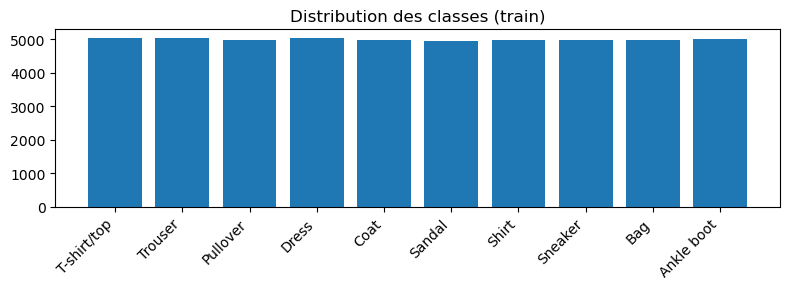

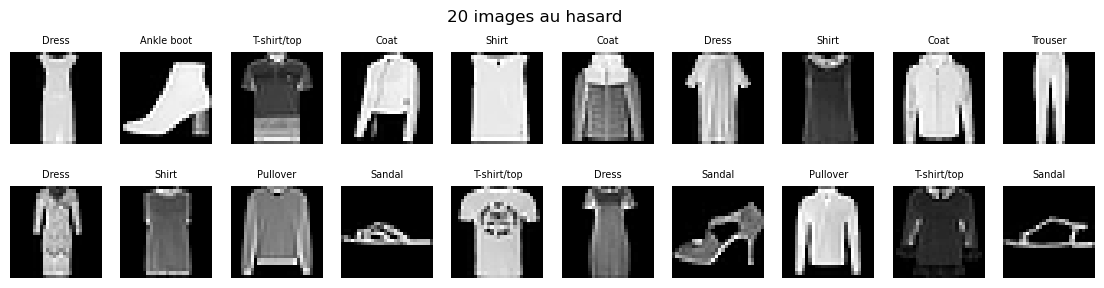

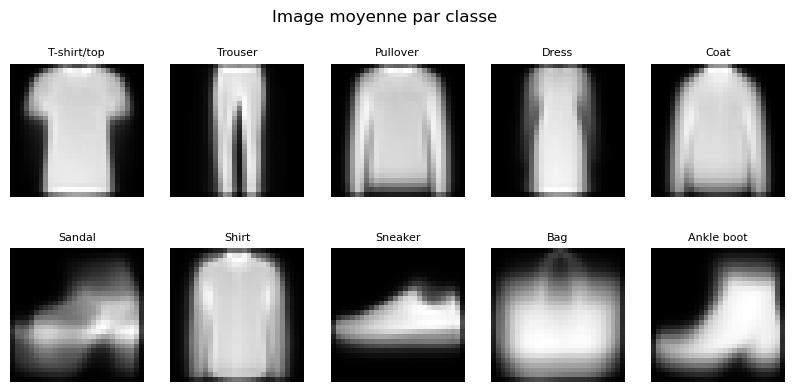

In [9]:
# 1. Distribution des classes
counts = np.bincount(y_train, minlength=10)
print(dict(zip(CLASSES, counts)))
plt.figure(figsize=(8, 3)); plt.bar(range(10), counts); plt.xticks(range(10), CLASSES, rotation=45, ha="right")
plt.title("Distribution des classes (train)"); plt.tight_layout(); plt.show()

# 2. 20 images au hasard
sel = rng.choice(len(X_train), 20, replace=False)
fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for ax, i in zip(axes.ravel(), sel):
    ax.imshow(X_train[i].reshape(28, 28), cmap="gray"); ax.set_title(CLASSES[y_train[i]], fontsize=7); ax.axis("off")
plt.suptitle("20 images au hasard"); plt.show()

# 3. Image moyenne par classe
fig, axes = plt.subplots(2, 5, figsize=(10, 4.4))
for c, ax in enumerate(axes.ravel()):
    ax.imshow(X_train[y_train == c].mean(axis=0).reshape(28, 28), cmap="gray"); ax.set_title(CLASSES[c], fontsize=8); ax.axis("off")
plt.suptitle("Image moyenne par classe"); plt.show()


### B2. PCA « à la main » avec la SVD
Standardiser, calculer les composantes, projeter en 2D, tracer la variance cumulée. Puis comparer à scikit-learn.

PC1 : 29.2% | PC2 : 17.7% | k pour 90 % de variance : 83


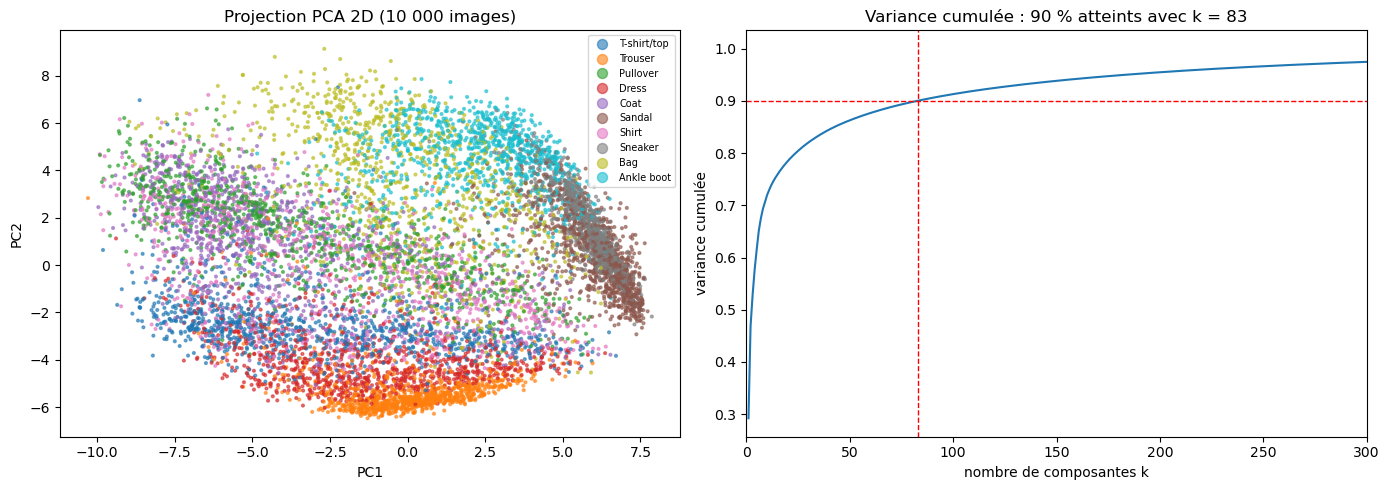

Z identique à sklearn au signe près : True
variance expliquée sklearn : [0.2919169  0.17694084] | à la main : [0.29191265 0.17694145]


In [10]:
Xs = X_train[:10000]; ys = y_train[:10000]
mu = Xs.mean(axis=0); Xc = Xs - mu
U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
var_exp = S**2 / np.sum(S**2)                  # part de variance expliquée par chaque composante
cum_var = np.cumsum(var_exp)
k90 = int(np.argmax(cum_var >= 0.90)) + 1      # 1er indice où la variance cumulée dépasse 90 % (+1 : comptage à partir de 1)
Z = Xc @ Vt[:2].T                              # projection 2D, forme (10000, 2)
assert Z.shape == (10000, 2)
print(f"PC1 : {var_exp[0]:.1%} | PC2 : {var_exp[1]:.1%} | k pour 90 % de variance : {k90}")

# scatter coloré par classe + courbe de variance cumulée
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
sc = ax1.scatter(Z[:, 0], Z[:, 1], c=ys, cmap="tab10", s=4, alpha=0.6)
handles, _ = sc.legend_elements()
ax1.legend(handles, CLASSES, fontsize=7, loc="best", markerscale=1.2)
ax1.set_xlabel("PC1"); ax1.set_ylabel("PC2"); ax1.set_title("Projection PCA 2D (10 000 images)")
ax2.plot(np.arange(1, len(cum_var) + 1), cum_var)
ax2.axhline(0.90, color="r", ls="--", lw=1); ax2.axvline(k90, color="r", ls="--", lw=1)
ax2.set_xlabel("nombre de composantes k"); ax2.set_ylabel("variance cumulée"); ax2.set_title(f"Variance cumulée : 90 % atteints avec k = {k90}")
ax2.set_xlim(0, 300); plt.tight_layout(); plt.show()

# comparaison avec sklearn (au signe près)
from sklearn.decomposition import PCA
pca = PCA(n_components=2).fit(Xs)
Z_sk = pca.transform(Xs)
print("Z identique à sklearn au signe près :", np.allclose(np.abs(Z), np.abs(Z_sk), atol=1e-3))
print("variance expliquée sklearn :", pca.explained_variance_ratio_, "| à la main :", var_exp[:2])


### B3. Reconstruction
Reconstruire une image avec k = 2, 12, 50, 200 composantes et observer.

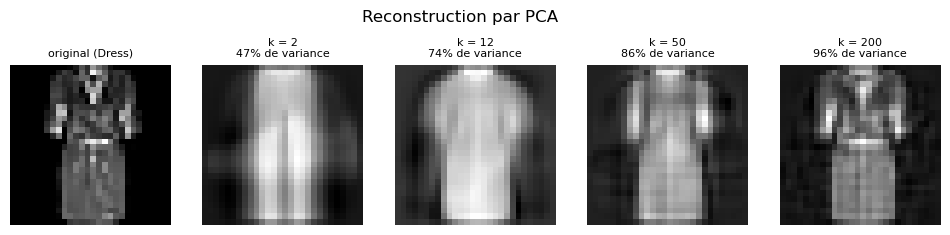

In [11]:
i = 7
ks = [2, 12, 50, 200]
fig, axes = plt.subplots(1, len(ks) + 1, figsize=(12, 2.8))
axes[0].imshow(Xs[i].reshape(28, 28), cmap="gray"); axes[0].set_title(f"original ({CLASSES[ys[i]]})", fontsize=8); axes[0].axis("off")
for ax, k in zip(axes[1:], ks):
    Zk = Xc[i] @ Vt[:k].T            # (k,) : coordonnées dans les k premières composantes
    rec = Zk @ Vt[:k] + mu           # (784,) : retour dans l'espace des pixels + moyenne
    ax.imshow(rec.reshape(28, 28), cmap="gray"); ax.set_title(f"k = {k}\n{cum_var[k-1]:.0%} de variance", fontsize=8); ax.axis("off")
plt.suptitle("Reconstruction par PCA"); plt.show()


## Partie C — Régression logistique from scratch (75 min)

Classifieur binaire **T-shirt (0) vs Pantalon (1)**. Convention du cours : `X` de forme `(n_x, m)`, `Y` de forme `(1, m)`.

In [12]:
def binary_subset(X, y, a=0, b=1):
    m = (y == a) | (y == b)
    return X[m].T.astype("float64"), (y[m] == b).astype("float64").reshape(1, -1)
Xb_train, Yb_train = binary_subset(X_train, y_train)
Xb_dev,   Yb_dev   = binary_subset(X_dev, y_dev)
print(Xb_train.shape, Yb_train.shape, Xb_dev.shape, "proportion de 1 :", Yb_train.mean())

(784, 10073) (1, 10073) (784, 1927) proportion de 1 : 0.4990568847413879


### C0. La baseline à battre
Avant tout modèle : la règle la plus simple. Classe majoritaire, puis une règle de bon sens : un pantalon a moins de pixels allumés qu'un T-shirt.

In [13]:
p1 = Yb_dev.mean()
acc_majoritaire = max(p1, 1 - p1)
luminosite = Xb_dev.sum(axis=0)
seuil = np.median(Xb_train.sum(axis=0))
pred_regle = (luminosite < seuil).astype("float64").reshape(1, -1)   # plus sombre que le seuil -> pantalon (1)
acc_regle = (pred_regle == Yb_dev).mean()
print(acc_majoritaire, acc_regle)


0.5049299429164504 0.7176959003632589


### C1. Les briques : sigmoïde, propagation, coût, gradients

In [14]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def propagate(w, b, X, Y):
    m = X.shape[1]
    A = sigmoid(w.T @ X + b)
    J = -np.mean(Y * np.log(A + 1e-8) + (1 - Y) * np.log(1 - A + 1e-8))
    dZ = A - Y                                                              # (1, m)
    dw = (X @ dZ.T) / m                                                     # (n_x, 1)
    db = np.sum(dZ) / m                                                     # scalaire
    assert dw.shape == w.shape
    return J, dw, db

# vérification : avec w = 0 et b = 0, A = 0.5 partout donc J = log 2 ≈ 0.693
J0, dw0, db0 = propagate(np.zeros((784, 1)), 0.0, Xb_train, Yb_train)
print(J0, np.log(2), dw0.shape, db0)


0.6931471605599454 0.6931471805599453 (784, 1) 0.0009431152586121314


### C2. Descente de gradient et prédiction

J final : 0.0419 | acc train : 0.9870 | acc dev : 0.9891


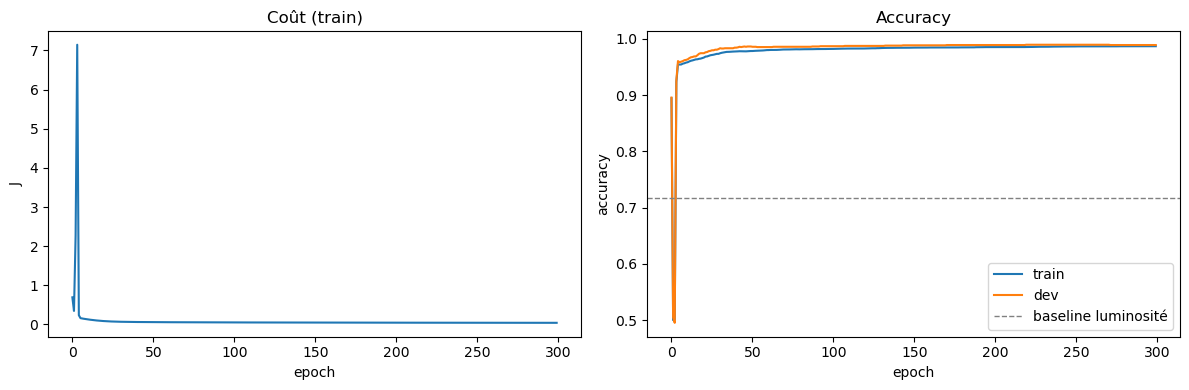

In [15]:
def train_logreg(X, Y, alpha=0.5, epochs=300, X_dev=None, Y_dev=None):
    n_x = X.shape[0]; w = np.zeros((n_x, 1)); b = 0.0
    hist = {"J": [], "acc_train": [], "acc_dev": []}
    for e in range(epochs):
        J, dw, db = propagate(w, b, X, Y)
        w = w - alpha * dw                                   # descente de gradient
        b = b - alpha * db
        hist["J"].append(J)
        hist["acc_train"].append(accuracy(w, b, X, Y))
        if X_dev is not None:
            hist["acc_dev"].append(accuracy(w, b, X_dev, Y_dev))
    return w, b, hist

def predict(w, b, X): return (sigmoid(w.T @ X + b) > 0.5).astype("float64")    # (1, m), seuil 0.5
def accuracy(w, b, X, Y): return (predict(w, b, X) == Y).mean()

w, b, hist = train_logreg(Xb_train, Yb_train, alpha=0.5, epochs=300, X_dev=Xb_dev, Y_dev=Yb_dev)
print(f"J final : {hist['J'][-1]:.4f} | acc train : {hist['acc_train'][-1]:.4f} | acc dev : {hist['acc_dev'][-1]:.4f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(hist["J"]); ax1.set_xlabel("epoch"); ax1.set_ylabel("J"); ax1.set_title("Coût (train)")
ax2.plot(hist["acc_train"], label="train"); ax2.plot(hist["acc_dev"], label="dev")
ax2.axhline(acc_regle, color="gray", ls="--", lw=1, label="baseline luminosité")
ax2.set_xlabel("epoch"); ax2.set_ylabel("accuracy"); ax2.set_title("Accuracy"); ax2.legend()
plt.tight_layout(); plt.show()


### C3. Effet du taux d'apprentissage
Comparer α ∈ {0,01 ; 0,1 ; 0,5 ; 3}. Lequel diverge ? Lequel est trop lent ?

α = 0.01  | J final : 0.1693 | J max : 0.69 | acc dev : 0.9699
α = 0.1   | J final : 0.0694 | J max : 0.69 | acc dev : 0.9855
α = 0.5   | J final : 0.0378 | J max : 5.94 | acc dev : 0.9865
α = 3.0   | J final : 0.0363 | J max : 9.31 | acc dev : 0.9865


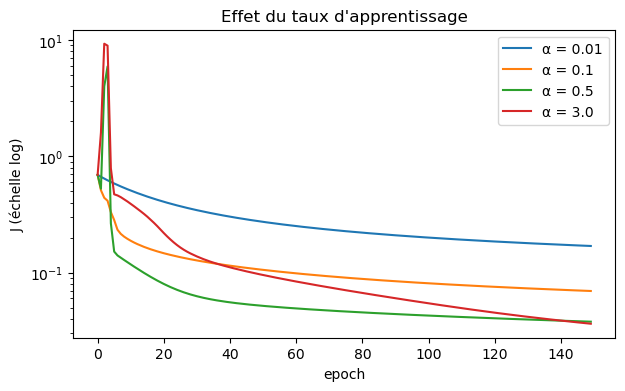

In [16]:
Xsub, Ysub = Xb_train[:, :2000], Yb_train[:, :2000]
plt.figure(figsize=(7, 4))
for alpha in [0.01, 0.1, 0.5, 3.0]:
    with np.errstate(over="ignore"):    # alpha = 3 peut faire déborder exp dans la sigmoïde
        _, _, h = train_logreg(Xsub, Ysub, alpha=alpha, epochs=150, X_dev=Xb_dev, Y_dev=Yb_dev)   # w, b de C2 non écrasés
    plt.plot(h["J"], label=f"α = {alpha}")
    print(f"α = {alpha:<5} | J final : {h['J'][-1]:.4f} | J max : {max(h['J']):.2f} | acc dev : {h['acc_dev'][-1]:.4f}")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("J (échelle log)"); plt.title("Effet du taux d'apprentissage")
plt.legend(); plt.show()


### C4. Interpréter les poids
Afficher `w` sous forme d'image 28×28 : où le modèle « regarde »-t-il pour distinguer un pantalon d'un T-shirt ?

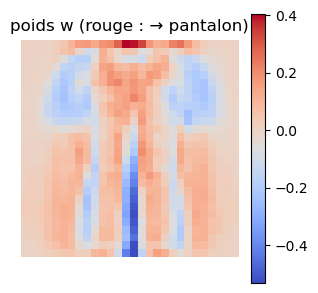

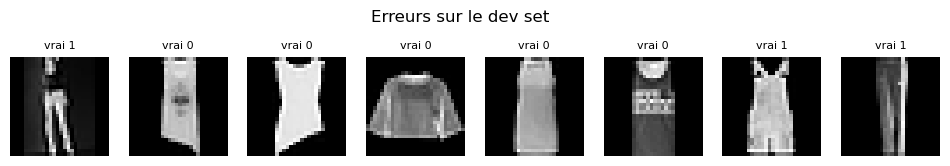

In [17]:
plt.figure(figsize=(3.5, 3.5)); plt.imshow(w.reshape(28, 28), cmap="coolwarm"); plt.colorbar(); plt.title("poids w (rouge : → pantalon)"); plt.axis("off"); plt.show()
errors = np.where(predict(w, b, Xb_dev) != Yb_dev)[1][:8]
fig, axes = plt.subplots(1, len(errors), figsize=(12, 2))
for ax, i in zip(axes, errors): ax.imshow(Xb_dev[:, i].reshape(28, 28), cmap="gray"); ax.set_title(f"vrai {int(Yb_dev[0, i])}", fontsize=8); ax.axis("off")
plt.suptitle("Erreurs sur le dev set"); plt.show()

## Pour aller plus loin
- Backpropagation à la main, comme sur la slide de l'appartement : x = 50, y = 150, w = 2, b = 10, J = (ŷ − y)². Écrire en NumPy la passe avant (ŷ, J), la passe arrière (dJ/dŷ, dJ/dw, dJ/db) et dix mises à jour avec α = 0,0001 ; vérifier que J passe de 1 600 à 400 puis à 100, et observer ce qui se passe avec α = 0,01.
- Remplacer la boucle sur les epochs par des mini-batchs de 64 : que devient la courbe de coût ?
- Étendre à 10 classes avec un softmax (`Z` de forme `(10, m)`, `dZ = A − Y_onehot`) — c'est le TP2.
- Comparer la PCA à 50 composantes + régression logistique vs 784 pixels : gain de temps ? perte de précision ?

### Bonus 1. Backpropagation à la main
x = 50, y = 150, w = 2, b = 10, J = (ŷ − y)². Passe avant, passe arrière, dix mises à jour.

In [18]:
bx, by, bw, bb = 50.0, 150.0, 2.0, 10.0

def backprop_demo(alpha, steps=10):
    w_, b_ = bw, bb
    Js = []
    for _ in range(steps):
        y_hat = w_ * bx + b_               # passe avant
        J = (y_hat - by) ** 2
        dJ_dyhat = 2 * (y_hat - by)        # passe arrière
        dJ_dw = dJ_dyhat * bx
        dJ_db = dJ_dyhat
        w_ = w_ - alpha * dJ_dw            # mise à jour
        b_ = b_ - alpha * dJ_db
        Js.append(J)
    return Js

print("α = 0.0001 :", [f"{J:.1f}" for J in backprop_demo(1e-4)])   # 1600 -> 400 -> 100 -> ...
print("α = 0.01   :", [f"{J:.3g}" for J in backprop_demo(1e-2)])   # le pas est trop grand : J explose


α = 0.0001 : ['1600.0', '399.7', '99.8', '24.9', '6.2', '1.6', '0.4', '0.1', '0.0', '0.0']
α = 0.01   : ['1.6e+03', '3.84e+06', '9.24e+09', '2.22e+13', '5.33e+16', '1.28e+20', '3.08e+23', '7.4e+26', '1.78e+30', '4.27e+33']


### Bonus 2. Mini-batchs de 64
Une mise à jour par paquet de 64 exemples au lieu d'une par epoch : comparer la courbe de coût.

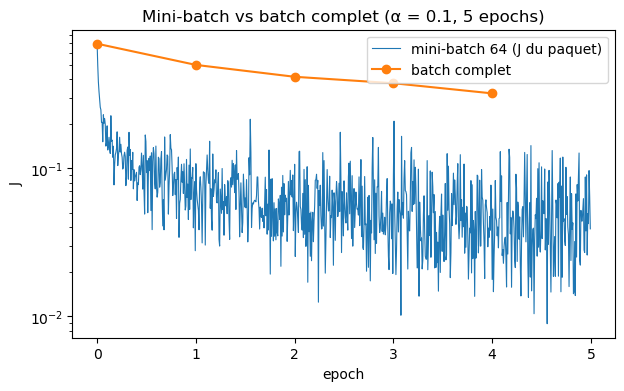

acc dev mini-batch : 0.9875 | batch complet : 0.9429


In [19]:
def train_minibatch(X, Y, alpha=0.1, epochs=5, batch_size=64, seed=0):
    rng_mb = np.random.default_rng(seed)
    m = X.shape[1]; w_ = np.zeros((X.shape[0], 1)); b_ = 0.0
    J_steps = []
    for e in range(epochs):
        perm = rng_mb.permutation(m)                          # on mélange à chaque epoch
        for k0 in range(0, m, batch_size):
            ib = perm[k0:k0 + batch_size]
            J, dw, db = propagate(w_, b_, X[:, ib], Y[:, ib])
            w_ = w_ - alpha * dw
            b_ = b_ - alpha * db
            J_steps.append(J)
    return w_, b_, J_steps

w_mb, b_mb, J_steps = train_minibatch(Xb_train, Yb_train, alpha=0.1, epochs=5)
w_fb, b_fb, h_fb = train_logreg(Xb_train, Yb_train, alpha=0.1, epochs=5)   # batch complet : 1 mise à jour par epoch

steps_per_epoch = int(np.ceil(Xb_train.shape[1] / 64))
plt.figure(figsize=(7, 4))
plt.plot(np.arange(len(J_steps)) / steps_per_epoch, J_steps, lw=0.8, label="mini-batch 64 (J du paquet)")
plt.plot(np.arange(5), h_fb["J"], "o-", label="batch complet")
plt.xlabel("epoch"); plt.ylabel("J"); plt.yscale("log"); plt.title("Mini-batch vs batch complet (α = 0.1, 5 epochs)"); plt.legend(); plt.show()
print(f"acc dev mini-batch : {accuracy(w_mb, b_mb, Xb_dev, Yb_dev):.4f} | batch complet : {accuracy(w_fb, b_fb, Xb_dev, Yb_dev):.4f}")


### Bonus 3. Softmax à 10 classes
`Z` de forme `(10, m)`, `dZ = A − Y_onehot` : même structure que la régression logistique (aperçu du TP2).

J final : 0.6171 | acc dev (10 classes) : 0.8016  (hasard : 0.10)


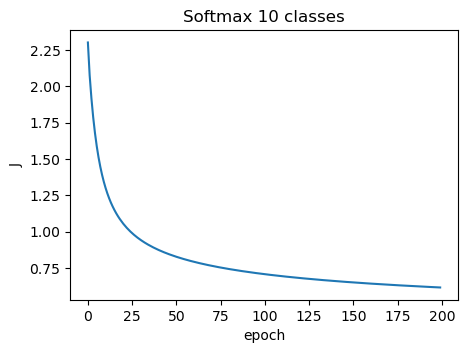

In [20]:
def softmax(Z):
    E = np.exp(Z - Z.max(axis=0, keepdims=True))      # on retire le max : stabilité numérique
    return E / E.sum(axis=0, keepdims=True)

X10_train = X_train.T.astype("float64"); X10_dev = X_dev.T.astype("float64")    # (784, m)
Y10_train = np.eye(10)[y_train].T                                                # (10, m) one-hot
m10 = X10_train.shape[1]
W10 = np.zeros((784, 10)); b10 = np.zeros((10, 1)); J10 = []
alpha10 = 0.1                                                                    # 0.5 oscille ici : 10 classes, pas plus petit

for e in range(200):
    A10 = softmax(W10.T @ X10_train + b10)                          # (10, m)
    J10.append(-np.mean(np.sum(Y10_train * np.log(A10 + 1e-8), axis=0)))
    dZ10 = A10 - Y10_train                                          # (10, m)
    W10 = W10 - alpha10 * (X10_train @ dZ10.T) / m10                # (784, 10)
    b10 = b10 - alpha10 * dZ10.mean(axis=1, keepdims=True)          # (10, 1)

pred10 = np.argmax(softmax(W10.T @ X10_dev + b10), axis=0)
print(f"J final : {J10[-1]:.4f} | acc dev (10 classes) : {(pred10 == y_dev).mean():.4f}  (hasard : 0.10)")
plt.figure(figsize=(5, 3.5)); plt.plot(J10); plt.xlabel("epoch"); plt.ylabel("J"); plt.title("Softmax 10 classes"); plt.show()


### Bonus 4. PCA à 50 composantes + régression logistique
Même classifieur T-shirt vs Pantalon, sur 50 features au lieu de 784 pixels : gain de temps ? perte de précision ?

In [21]:
P = Vt[:50]                                            # (50, 784) : composantes calculées en B2
mu_pca = Xs.mean(axis=0).reshape(-1, 1)                # (784, 1)
Xp_train = P @ (Xb_train - mu_pca)                     # (50, m)
Xp_dev   = P @ (Xb_dev - mu_pca)

t0 = time.perf_counter(); w_pix, b_pix, h_pix = train_logreg(Xb_train, Yb_train, alpha=0.5, epochs=300); t_pix = time.perf_counter() - t0
t0 = time.perf_counter(); w_pca, b_pca, h_pca = train_logreg(Xp_train, Yb_train, alpha=0.5, epochs=300); t_pca = time.perf_counter() - t0

print(f"784 pixels : {t_pix:.2f} s | acc dev : {accuracy(w_pix, b_pix, Xb_dev, Yb_dev):.4f}")
print(f"PCA 50     : {t_pca:.2f} s | acc dev : {accuracy(w_pca, b_pca, Xp_dev, Yb_dev):.4f}")


784 pixels : 0.81 s | acc dev : 0.9891
PCA 50     : 0.29 s | acc dev : 0.9855
